# Küçültme / Ölçek Deneyi — Efe

**Tek değişken: ölçek katsayısı** (1.0, 0.75, 0.5, 0.25; INTER_AREA). Baş ROI ve baret kutuları aynı katsayıyla dönüştürülür; renk aralıkları ve karar eşikleri sabit.
Ayrı gösterimde küçültülen görüntü eski boyutuna büyütülür: **büyütme kaybolan ayrıntıyı geri getirmez (S5).**

In [1]:
from pathlib import Path
import sys
KOK = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "kaynak" / "analiz.py").is_file())
sys.path.insert(0, str(KOK))

import cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from kaynak.veri import ayarlari_oku, veri_setini_oku, goruntu_oku, maske_oku
from kaynak.analiz import analiz_et
from kaynak.gorsel import bgr2rgb, kutulari_ciz, maske_bindir
ayarlar = ayarlari_oku()
kayitlar = veri_setini_oku()
pd.set_option("display.max_colwidth", 80)
print("Görüntüler:", ", ".join(f"{k['kimlik']} ({k['bolum']})" for k in kayitlar))

Görüntüler: G1 (gelistirme), G2 (gelistirme), K1 (kontrol), K2 (kontrol), K3 (kontrol), K4 (kontrol)


## 1. Deney öncesi tahmin

In [2]:
tahminler = pd.read_csv(KOK / "belgeler/tahminler.csv")
benim = tahminler[(tahminler.uye == "Efe")]
if benim.empty:
    print("UYARI: Bu deney için kayıtlı tahmin yok. Hoca: 'Tahmini olmayan deney puanlanmaz.'")
    print("Deneyi çalıştırmadan ÖNCE belgeler/tahminler.csv dosyasına iki cümle ekleyin.")
for _, t in benim.iterrows():
    print(f"[{t.kayit_tarihi}] {t.deney_kimligi}\n 1) {t.tahmin_1}\n 2) {t.tahmin_2}\n   ({t.durum})\n")

UYARI: Bu deney için kayıtlı tahmin yok. Hoca: 'Tahmini olmayan deney puanlanmaz.'
Deneyi çalıştırmadan ÖNCE belgeler/tahminler.csv dosyasına iki cümle ekleyin.


## 2. Sonuçlar

In [3]:
o = pd.read_csv(KOK / "sonuclar/olcek/olcek_sonuclari.csv")
o[["kimlik", "olcek", "boyut", "en_kucuk_baret_piksel", "yontem", "maske_alani_yuzde", "bas_ortusmesi_yuzde", "kural_sinifi", "dogru_mu", "tp", "fp", "fn"]]

,kimlik,olcek,boyut,en_kucuk_baret_piksel,yontem,maske_alani_yuzde,bas_ortusmesi_yuzde,kural_sinifi,dogru_mu,tp,fp,fn
0,K1,1.00,1280x853,34132.0,RGB,0.40,6.08,baret_yok,hayir,0,2,1
1,K1,1.00,1280x853,34132.0,HSV,0.81,12.69,baret_yok,hayir,1,0,0
2,K1,0.75,960x640,19239.0,RGB,0.40,6.05,baret_yok,hayir,0,1,1
3,K1,0.75,960x640,19239.0,HSV,0.81,12.70,baret_yok,hayir,1,0,0
4,K1,0.50,640x426,8667.0,RGB,0.39,5.95,baret_yok,hayir,0,1,1
5,K1,0.50,640x426,8667.0,HSV,0.82,12.69,baret_yok,hayir,1,0,0
6,K1,0.25,320x213,2214.0,RGB,0.39,5.87,baret_yok,hayir,0,1,1
7,K1,0.25,320x213,2214.0,HSV,0.81,12.57,baret_yok,hayir,0,1,1
8,K2,1.00,2121x1414,1050.0,RGB,0.03,17.74,baret_yok,hayir,0,3,2
9,K2,1.00,2121x1414,1050.0,HSV,0.03,17.88,baret_yok,hayir,1,2,1


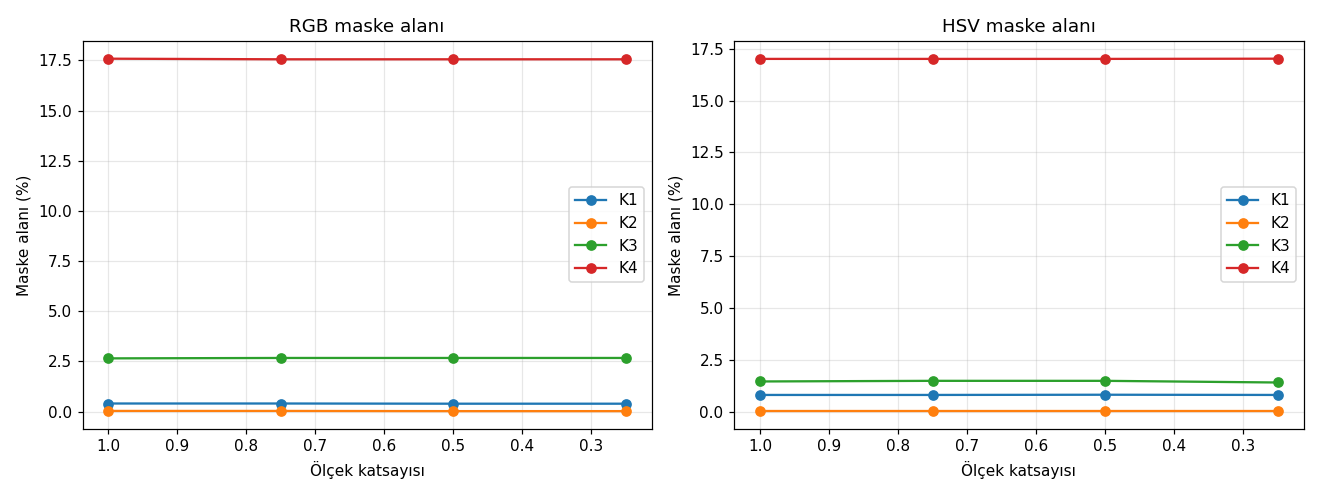

In [4]:
from IPython.display import Image, display
display(Image(filename=str(KOK / "sonuclar/olcek/olcek_maske_alani.png")))

## 3. Geri büyütme (S5)

,kimlik,olcek,ortalama_mutlak_fark,psnr_db
0,K1,0.75,0.49,43.25
1,K1,0.50,0.77,39.81
2,K1,0.25,1.44,34.88
3,K2,0.75,2.54,34.43
4,K2,0.50,3.45,31.55
5,K2,0.25,5.26,27.52
6,K3,0.75,0.87,41.70
7,K3,0.50,1.33,38.09
8,K3,0.25,2.74,32.42
9,K4,0.75,1.72,36.28


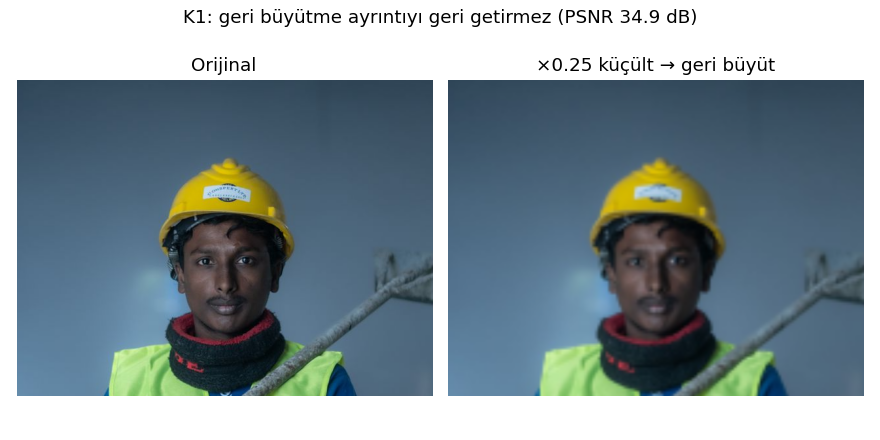

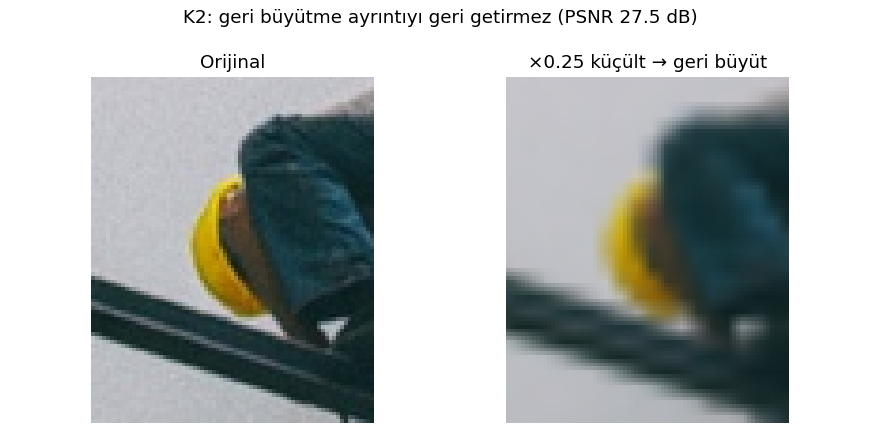

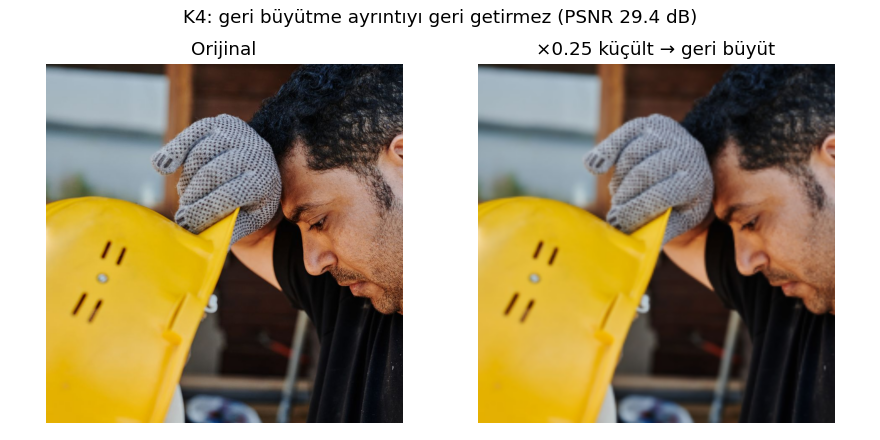

In [5]:
display(pd.read_csv(KOK / "sonuclar/olcek/geri_buyutme.csv"))
for yol in sorted((KOK / "sonuclar/olcek").glob("*_geri_buyutme.png")):
    display(Image(filename=str(yol), width=700))

## 4. Yorum
*(Üye yazar: en az bir kaçırma veya dayanıklılık sınırı.)*